# **Membuat Model Machine Learning dengan Data Time Series**

# **Nama : Doni Firmansyah**

In [1]:
# @markdown Import Library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

In [3]:
# @markdown Collecting Data :\
# @markdown Dataset yang digunakan adalah dari https://www.kaggle.com/datasets/mnassrib/jena-weather-dataset

# unzip file
!unzip jena_weather_2004_2020.zip
# baca file csv menjadi dataframe
df = pd.read_csv('jena_weather_2004_2020.csv')
# ambil data tanggal dan temp sebanyak 200254 baris
df = df[["Date Time","T (degC)"]][-200254::]
# rename columns
df.rename(columns={"Date Time":"datetime","T (degC)":"temp"},inplace=True)

Archive:  jena_weather_2004_2020.zip
replace jena_weather_2004_2020.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

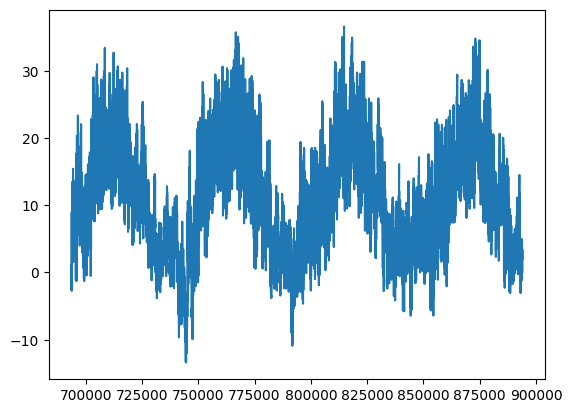

In [4]:
# @markdown Visualizing Data

# cek dataset temp
plt.plot(df["temp"])
plt.show()

In [5]:
# @markdown Cleaning Data

print(f"Jumlah Data\n{df.count()}\n")

# cek duplikat
print(f"Jumlah Data Duplikat {df.duplicated().sum()}\n")
df.drop_duplicates(inplace=True)

# cek data kosong
print(f"Jumlah Data Kosong\n{df.isnull().sum()}\n")
df.dropna(inplace=True)

print(f"Jumlah Setelah Dibersihkan\n{df.count()}\n")

Jumlah Data
datetime    200254
temp        200254
dtype: int64

Jumlah Data Duplikat 1

Jumlah Data Kosong
datetime    0
temp        0
dtype: int64

Jumlah Setelah Dibersihkan
datetime    200253
temp        200253
dtype: int64



In [6]:
# @markdown Pre-Processing Data :\
# @markdown Normalization

# membuat array [num1 ... numN] menjadi [[num1] [...] [numN]]
dataTemp = tf.expand_dims(df['temp'].values, axis=-1)

# Normalization
scaler = MinMaxScaler()
scaledDataTemp = scaler.fit_transform(dataTemp)

In [7]:
# @markdown Pre-Processing Data:\
# @markdown Split Data

trainData, testData = train_test_split(scaledDataTemp, test_size = 0.2, shuffle=False)
print(f"Jumlah Baris Data Train : {trainData.shape[0]}")
print(f"Jumlah Baris Data Test : {testData.shape[0]}")

Jumlah Baris Data Train : 160202
Jumlah Baris Data Test : 40051


In [8]:
# @markdown Pre-Processing Data:\
# @markdown Checking Threshold

threshold_mae_train = (trainData.max() - trainData.min()) * 10/100
threshold_mae_test = (testData.max() - testData.min()) * 10/100
print(f"Train Threshold : {threshold_mae_train} Test Threshold : {threshold_mae_test}")

Train Threshold : 0.1 Test Threshold : 0.0824


In [9]:
# @markdown Pre-Processing Data :\
# @markdown windowed data

def windowed_dataset(series, window_size, batch_size, shuffle_buffer):
    # membuat array [[num1] [...] [numN]] menjadi [[[num1]],[[...]],[[numN]]]
    ds = tf.data.Dataset.from_tensor_slices(series)
    # membuat window dengan jumlah isi yang telah ditentukan
    ds = ds.window(window_size + 1, shift=1, drop_remainder=True)
    # membuat array menjadi [[num1] [...] [numN]]
    ds = ds.flat_map(lambda w: w.batch(window_size + 1))
    # dibuat acak
    ds = ds.shuffle(shuffle_buffer)
    # mapping
    ds = ds.map(lambda w: (w[:-1], w[-1:]))
    return ds.batch(batch_size).prefetch(1)

batchSize = 4464
windowedTrainData = windowed_dataset(trainData, window_size=144, batch_size=batchSize, shuffle_buffer=1000)
windowedTestData = windowed_dataset(testData, window_size=144, batch_size=batchSize, shuffle_buffer=1000)

In [21]:
# @markdown Pre-Processing Data :\
# @markdown Modelling

model = tf.keras.models.Sequential([
  tf.keras.layers.LSTM(60, return_sequences=True),
  tf.keras.layers.LSTM(60),
  tf.keras.layers.Dense(30, activation="relu"),
  tf.keras.layers.Dense(10, activation="relu"),
  tf.keras.layers.Dense(1)
])

optimizer = tf.keras.optimizers.SGD(learning_rate=10.0000e-04, momentum=0.9)
model.compile(loss=tf.keras.losses.Huber(),
              optimizer=optimizer,
              metrics=["mae"])

In [17]:
# @markdown Pre-Processing Data :\
# @markdown Creating Callback

class CustomCallback(tf.keras.callbacks.Callback):

    def on_epoch_end(self, epoch, logs=None):
        if logs.get("mae") < threshold_mae_train and logs.get("val_mae") < threshold_mae_test:
            print(f"Training and Validation on epoch {epoch+1} get minimum and MAE (10%)")
            self.model.stop_training = True

In [22]:
# @markdown Processing Data :\
# @markdown Fitting

history = model.fit(windowedTrainData,epochs=100,verbose=2,validation_data=windowedTestData,callbacks=[CustomCallback()])

Epoch 1/100
36/36 - 71s - loss: 0.0627 - mae: 0.3080 - val_loss: 0.0237 - val_mae: 0.1842 - 71s/epoch - 2s/step
Epoch 2/100
36/36 - 54s - loss: 0.0120 - mae: 0.1250 - val_loss: 0.0075 - val_mae: 0.0999 - 54s/epoch - 1s/step
Epoch 3/100
36/36 - 54s - loss: 0.0082 - mae: 0.1059 - val_loss: 0.0068 - val_mae: 0.0957 - 54s/epoch - 1s/step
Epoch 4/100
36/36 - 51s - loss: 0.0079 - mae: 0.1042 - val_loss: 0.0067 - val_mae: 0.0950 - 51s/epoch - 1s/step
Epoch 5/100
36/36 - 51s - loss: 0.0077 - mae: 0.1029 - val_loss: 0.0066 - val_mae: 0.0938 - 51s/epoch - 1s/step
Epoch 6/100
36/36 - 53s - loss: 0.0075 - mae: 0.1016 - val_loss: 0.0064 - val_mae: 0.0926 - 53s/epoch - 1s/step
Epoch 7/100
36/36 - 61s - loss: 0.0073 - mae: 0.1002 - val_loss: 0.0062 - val_mae: 0.0913 - 61s/epoch - 2s/step
Epoch 8/100
36/36 - 51s - loss: 0.0071 - mae: 0.0989 - val_loss: 0.0061 - val_mae: 0.0900 - 51s/epoch - 1s/step
Epoch 9/100
36/36 - 61s - loss: 0.0069 - mae: 0.0974 - val_loss: 0.0059 - val_mae: 0.0887 - 61s/epoch - 

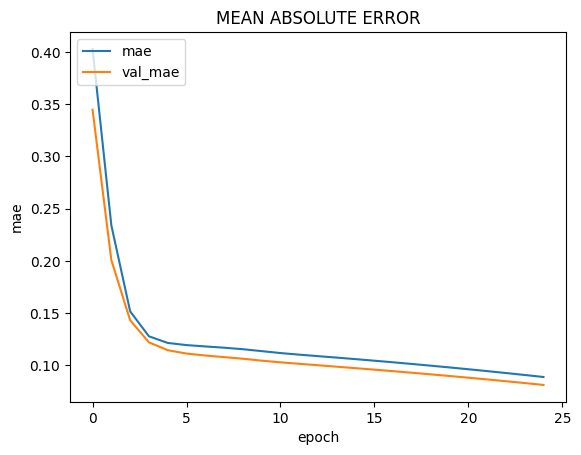

In [19]:
# @markdown Post-Processing :\
# @markdown Mean Absolute Error Visualization Result

plt.plot(history.history['mae'])
plt.plot(history.history['val_mae'])
plt.title('MEAN ABSOLUTE ERROR')
plt.ylabel('mae')
plt.xlabel('epoch')
plt.legend(['mae', 'val_mae'], loc='upper left')
plt.show()

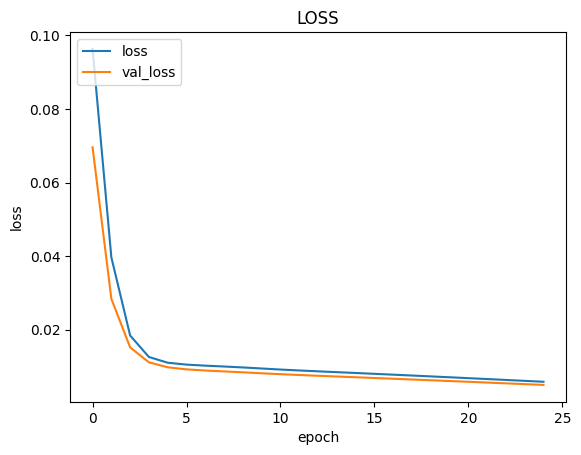

In [20]:
# @markdown Post-Processing :\
# @markdown Loss Visualization Result

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('LOSS')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['loss', 'val_loss'], loc='upper left')
plt.show()